<a href="https://colab.research.google.com/github/2026mcb1540-dotcom/Food-Delivery-Time-Prediction/blob/main/Food_Delivery_Time_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Our AI project as officialy started")

Our AI project as officialy started


In [4]:
df = pd.read_csv("Food_Delivery_Times.csv")
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [5]:
df.shape

(1000, 9)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [7]:
df.isnull().sum()

,0
Order_ID,0
Distance_km,0
Weather,30
Traffic_Level,30
Time_of_Day,30
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,30
Delivery_Time_min,0


In [8]:
df.describe()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000


In [9]:
df.describe(include="object")

,Weather,Traffic_Level,Time_of_Day,Vehicle_Type
count,970,970,970,1000
unique,5,3,4,3
top,Clear,Medium,Morning,Bike
freq,470,390,308,503


In [10]:
print("Duplicate rows:", df.duplicated().sum())
print("Unique Order IDs:", df['Order_ID'].nunique())

Duplicate rows: 0
Unique Order IDs: 1000


In [11]:
missing_rows = df[df.isnull().any(axis=1)]
print("Rows containing missing values:",
      len(missing_rows))
print("Missing values by column:")
print(missing_rows.isnull().sum())

Rows containing missing values: 117
Missing values by column:
Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64


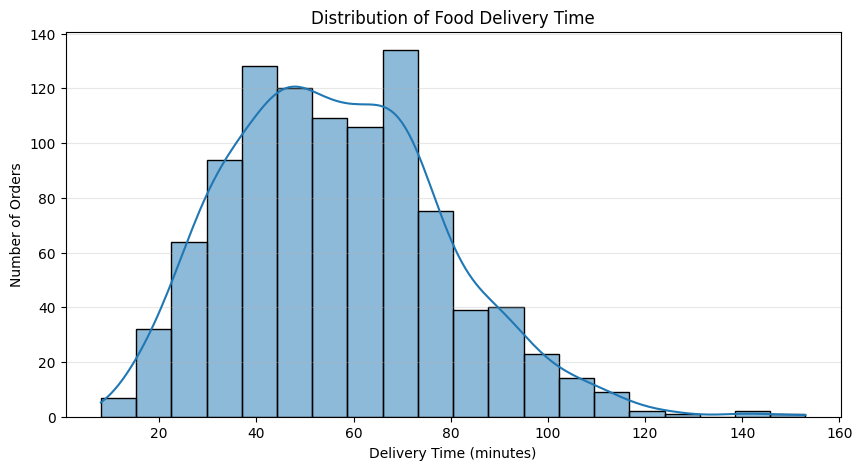

In [12]:
# Distribution of Delivery Time
plt.figure(figsize=(10, 5))
sns.histplot(data=df,x='Delivery_Time_min',bins=20,kde=True)

plt.title('Distribution of Food Delivery Time')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Number of Orders')

plt.grid(axis='y', alpha=0.3)
plt.show()

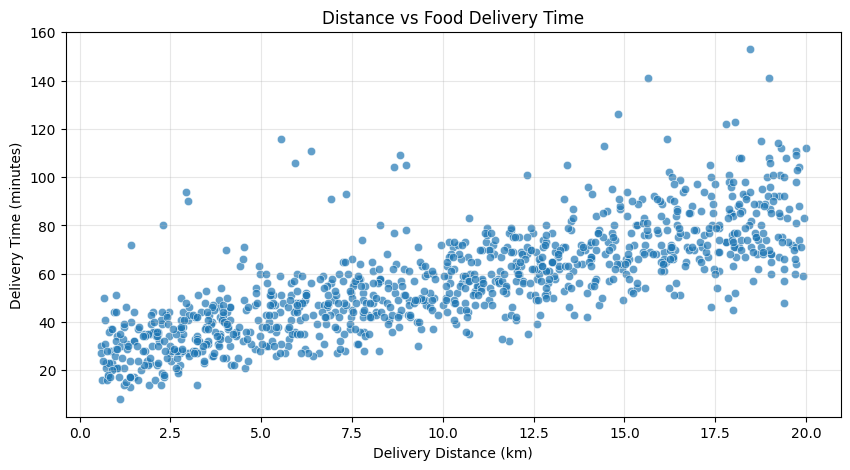

In [13]:
# Relationship between Distance and Delivery Time

plt.figure(figsize=(10, 5))

sns.scatterplot(data=df,x='Distance_km',y='Delivery_Time_min',alpha=0.7)
plt.title('Distance vs Food Delivery Time')
plt.xlabel('Delivery Distance (km)')
plt.ylabel('Delivery Time (minutes)')
plt.grid(alpha=0.3)
plt.show()

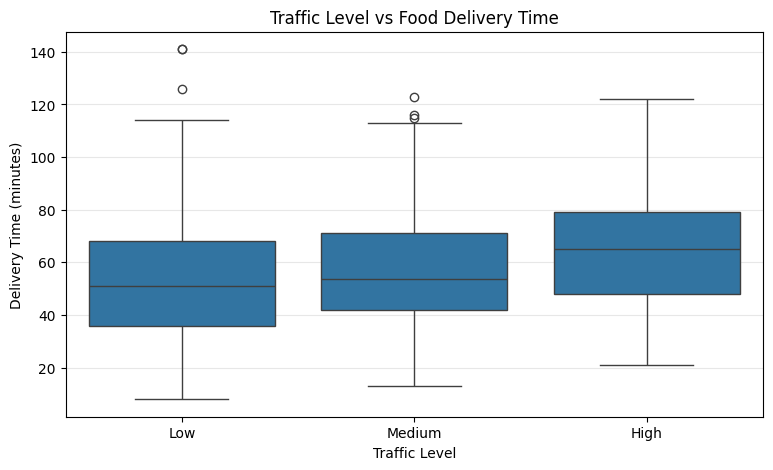

In [14]:
# Traffic Level vs Delivery Time

plt.figure(figsize=(9, 5))
sns.boxplot(data=df,x='Traffic_Level',y='Delivery_Time_min')
plt.title('Traffic Level vs Food Delivery Time')
plt.xlabel('Traffic Level')
plt.ylabel('Delivery Time (minutes)')
plt.grid(axis='y', alpha=0.3)
plt.show()

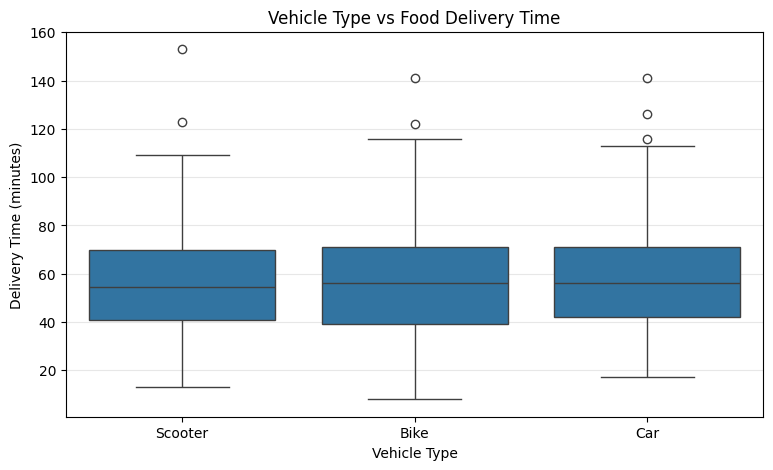

In [15]:
#Vehicle Type vs. Delivery Time

plt.figure(figsize=(9, 5))

sns.boxplot(data=df,x='Vehicle_Type',y='Delivery_Time_min')
plt.title('Vehicle Type vs Food Delivery Time')
plt.xlabel('Vehicle Type')
plt.ylabel('Delivery Time (minutes)')
plt.grid(axis='y', alpha=0.3)
plt.show()


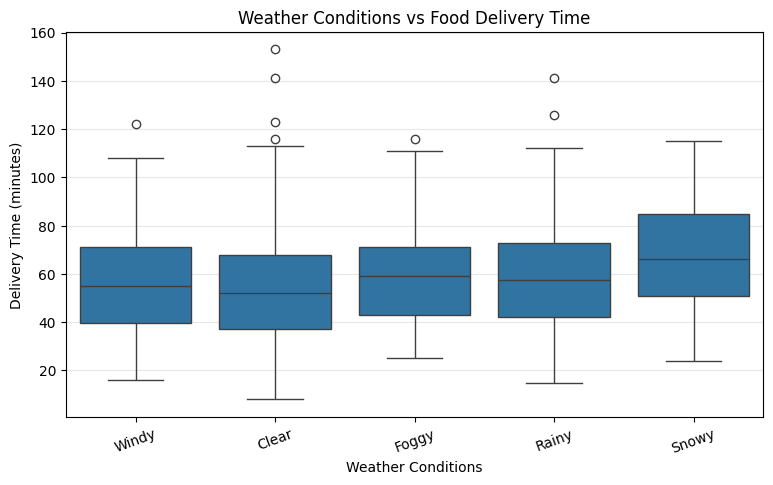

In [16]:
#Weather vs Delivery Time

plt.figure(figsize=(9, 5))

sns.boxplot(data=df,x='Weather',y='Delivery_Time_min')
plt.title('Weather Conditions vs Food Delivery Time')
plt.xlabel('Weather Conditions')
plt.ylabel('Delivery Time (minutes)')
plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)
plt.show()

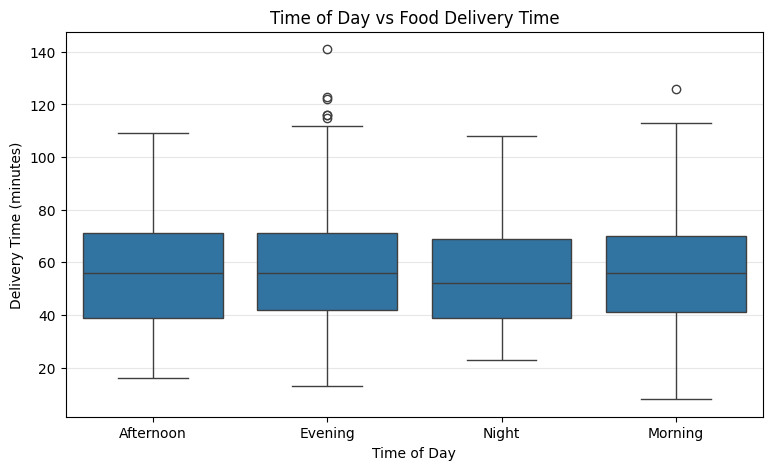

In [17]:
# Time of Day vs Delivery Time

plt.figure(figsize=(9, 5))

sns.boxplot(data=df,x='Time_of_Day',y='Delivery_Time_min')
plt.title('Time of Day vs Food Delivery Time')
plt.xlabel('Time of Day')
plt.ylabel('Delivery Time (minutes)')
plt.grid(axis='y', alpha=0.3)
plt.show()

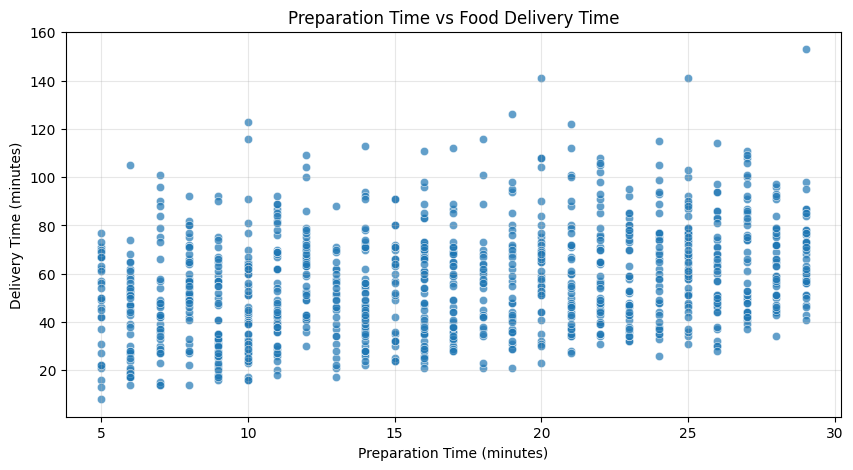

In [22]:
# Preparation Time vs Delivery Time

plt.figure(figsize=(10, 5))

sns.scatterplot(data=df,x='Preparation_Time_min',y='Delivery_Time_min',alpha=0.7)
plt.title('Preparation Time vs Food Delivery Time')
plt.xlabel('Preparation Time (minutes)')
plt.ylabel('Delivery Time (minutes)')
plt.grid(alpha=0.3)
plt.show()

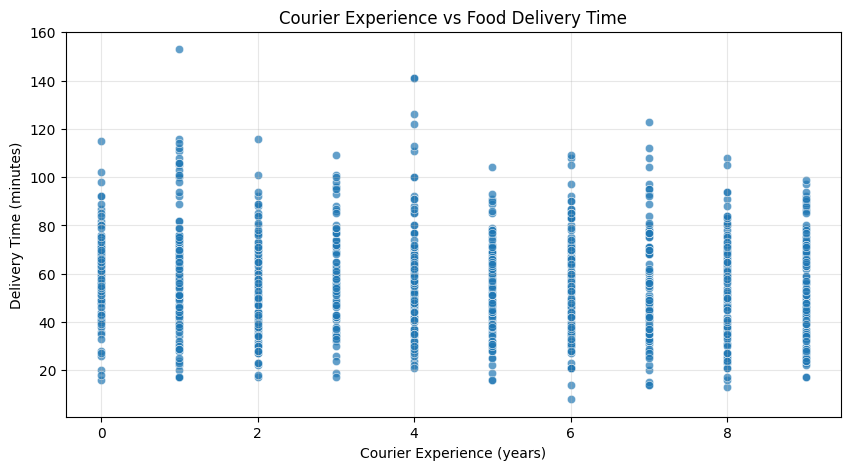

In [23]:
# Courier Experience vs Delivery Time

plt.figure(figsize=(10, 5))

sns.scatterplot(data=df,x='Courier_Experience_yrs',y='Delivery_Time_min',alpha=0.7)
plt.title('Courier Experience vs Food Delivery Time')
plt.xlabel('Courier Experience (years)')
plt.ylabel('Delivery Time (minutes)')
plt.grid(alpha=0.3)
plt.show()


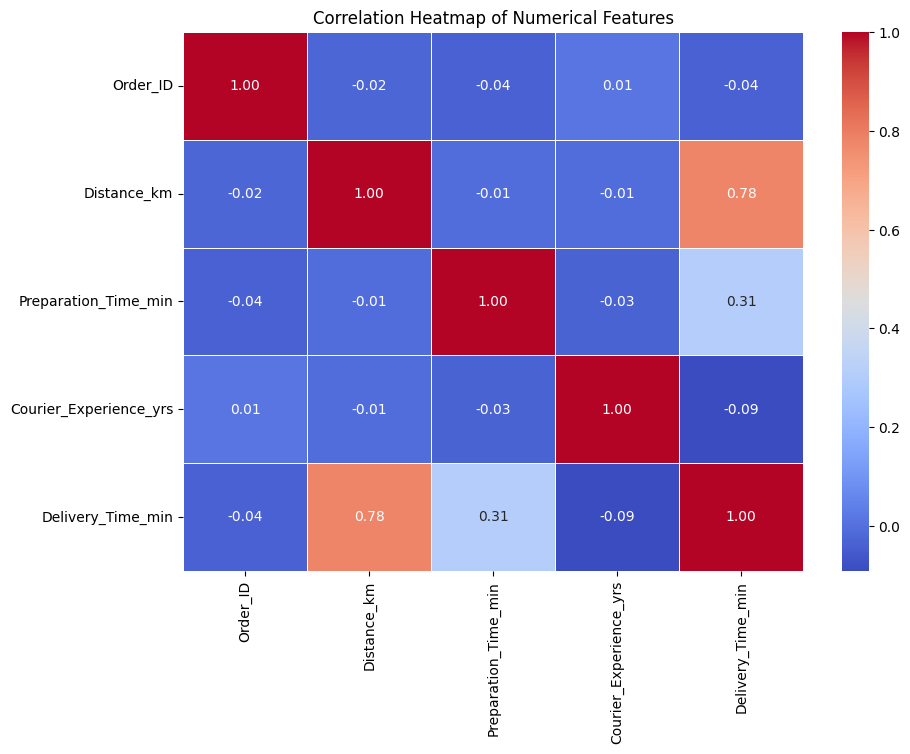

In [24]:
# Correlation Heatmap

plt.figure(figsize=(10, 7))
numeric_df = df.select_dtypes(include=np.number)
sns.heatmap(numeric_df.corr(),annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()